# Figure 5: Mixed vs. blocked SNR

Do participants set different bounds for low- and high-SNR trials, when the SNR is blocked (cohort 1,
OL: one SNR per block, so the SNR is known) and when it is mixed within a block (cohort 2, MX: the SNR
must be inferred during the trial)?

**Figure:** 2 rows (OL, MX) × 3 columns (blocks 1–3: no penalty, coin penalty, step penalty). Each
panel: the reward rate of every pair of fixed low- and high-SNR bounds (heatmap, coins per step; one
color scale for all panels), the near-optimal pairs (dotted red contour: reward rate ≥ 95% of the maximum; no single optimum is
marked, because the surfaces are nearly flat near their peak), each subject's low- and high-SNR
bound plateaus (white circles; triangles at the panel edge: edge fits, a plateau at a fit limit or > 0.78,
whose choices are not based on bound crossings, left out of the statistics and the median), the participants' median
(large black circle) and the Wilcoxon signed-rank p of hi − lo (upper left). The median difference
and the Spearman correlation of lo and hi are in the table at the end.

**Bounds:** the stopping model's bound plateau (fits by `scripts/run_stopping_fits.py`).
- OL: `stopping_fits_main.pkl`; low SNR = raw block b, high SNR = raw block b + 3 (each block has a
  single SNR).
- MX: `stopping_fits_mx_by_snr.pkl`, the same model with every per-block parameter separate for the
  low- and high-SNR trials of each block (groups `B<b>_lo`, `B<b>_hi`).

Fits use `get_stopping_model_trials` (trial_number ≥ 10, recorded choice, no DT cutoff, no wall-hit
exclusion, raw positions). **Edge fits:** a plateau at a fit limit (`get_plateau_at_limit`, 0.002 or 2.0) or above 0.78, past
the screen edge (0.75): no evidence-based stopping. A subject whose low- or high-SNR plateau is an
edge fit is left out of that panel's statistics and median (counts printed).

In [1]:
import sys
sys.path.insert(0, '..')

import pickle

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd
import scipy.stats

from pigeon.pathDefaults import DATA_DIR, FIGURES_DIR
from pigeon.plotting import (CM, FS, FS_INSET, CONDITION_LABELS, DATA_COLOR, MEDIAN_MARKER, OPTIMAL_COLOR,
                             TASK_ROW_LABELS, add_panel_label, format_p, format_rho, plot_subject_points,
                             use_figure_style)
from pigeon.simulation import BLOCK_DEFAULTS, get_simulated_data_table
from pigeon.stopping import get_plateau_at_limit

## Bound plateaus

In [2]:
# Bound plateaus, low and high SNR, per subject: fit_bounds[(task, block)] = (lo, hi); fit_limit marks
# edge fits, subjects with either plateau at a fit limit (0.002: commits on any movement; 2.0: never crosses) or
# beyond the panel (past the screen edge at 0.75, so the bound is essentially never reached). Either way their
# choices are not based on bound crossings: drawn as triangles at the panel edge, left out of the statistics.
PROCESSED = DATA_DIR
X_SHOW_MAX = 0.78   # fitted bounds above this are beyond the panel
_ol = pd.read_pickle(PROCESSED / 'stopping_fits_main.pkl').query("task == 'OL'").copy()
_mx = pd.read_pickle(PROCESSED / 'stopping_fits_mx_by_snr.pkl').query("task == 'MX'").copy()
for _f in (_ol, _mx):
    _f['at_limit'] = get_plateau_at_limit(_f)
_scale = {'OL': _ol.pivot(index='subject_index', columns='group', values='bound_scale'),
          'MX': _mx.pivot(index='subject_index', columns='group', values='bound_scale')}
_lim = {'OL': _ol.pivot(index='subject_index', columns='group', values='at_limit').fillna(False).astype(bool),
        'MX': _mx.pivot(index='subject_index', columns='group', values='at_limit').fillna(False).astype(bool)}
fit_limit = {}
_groups = {'OL': lambda b: (f'B{b}', f'B{b + 3}'), 'MX': lambda b: (f'B{b}_lo', f'B{b}_hi')}
fit_bounds = {}
for _task in ('OL', 'MX'):
    for _b in (1, 2, 3):
        _lo, _hi = _groups[_task](_b)
        fit_bounds[(_task, _b)] = (_scale[_task][_lo].to_numpy(), _scale[_task][_hi].to_numpy())
        fit_limit[(_task, _b)] = ((_lim[_task][_lo] | _lim[_task][_hi]).reindex(_scale[_task].index).to_numpy()
                                  | (fit_bounds[(_task, _b)][0] > X_SHOW_MAX) | (fit_bounds[(_task, _b)][1] > X_SHOW_MAX))
        _both = np.isfinite(fit_bounds[(_task, _b)][0]) & np.isfinite(fit_bounds[(_task, _b)][1])
        print(f'{_task} block {_b}: {_both.sum()} subjects with both fits; {np.sum(_both & fit_limit[(_task, _b)])} '
              f'left out (a plateau at a fit limit or > {X_SHOW_MAX}): {list(_scale[_task].index[_both & fit_limit[(_task, _b)]])}')

OL block 1: 60 subjects with both fits; 10 left out (a plateau at a fit limit or > 0.78): [4, 5, 13, 22, 43, 44, 51, 58, 59, 60]
OL block 2: 60 subjects with both fits; 5 left out (a plateau at a fit limit or > 0.78): [13, 22, 44, 51, 59]
OL block 3: 60 subjects with both fits; 4 left out (a plateau at a fit limit or > 0.78): [13, 39, 44, 55]
MX block 1: 60 subjects with both fits; 4 left out (a plateau at a fit limit or > 0.78): [18, 45, 53, 58]
MX block 2: 60 subjects with both fits; 4 left out (a plateau at a fit limit or > 0.78): [18, 53, 54, 58]
MX block 3: 60 subjects with both fits; 4 left out (a plateau at a fit limit or > 0.78): [27, 28, 53, 58]


## Reward-rate surfaces

Mean coins per block over a grid of fixed low- and high-SNR bounds (`get_simulated_data_table`: 300 simulated subjects per cell, 600-step blocks, the block's reward structure, non-decision time 1 or 2 steps with the cohort's mean fitted probabilities), cached in `data/processed/Figure05_rr_matrices.pkl` and reused only if the grid, subject count, generative means, NDT probabilities and seed match (the MX surfaces take ~45 min per block).

In [3]:
# ── Parameters ────────────────────────────────────────────────────────────────
BLOCKS      = [1, 2, 3]                     # no penalty, coin penalty, step penalty
STEPS_PER_BLOCK = BLOCK_DEFAULTS[1]['steps_per_block']
RR_BOUNDS   = np.arange(0.01, 0.82, 0.05)  # bound grid, 0.01-0.81 (17 values; to the panel edge)
NUM_RR_REPS = 300                           # simulated subjects per grid cell
G_MEANS     = [0.05, 0.15]                 # lo and hi SNR generative means
# NDT of the simulated trials: 1 or 2 steps, with each cohort's mean fitted probabilities
NDT_PROBS   = {task: (p1, 1 - p1) for task, p1 in
               ((t, float(f.groupby('subject_index').ndt_p1.first().mean())) for t, f in (('OL', _ol), ('MX', _mx)))}
HEATMAP_MARKER_SIZE = 6   # subject points read smaller over the heatmap than on white (shared size: 5)

rng = np.random.default_rng(42)


# ── Helper: simulate reward-rate matrix ───────────────────────────────────────
def compute_rr_matrix(task_type, block, rr_bounds, num_reps, g_means, rng):
    """Mean coins per block over a low-SNR-bound x high-SNR-bound grid, as rr_matrix[hi_idx, lo_idx].

    OL (blocked SNR): the low- and high-SNR blocks are simulated separately for each bound and their
    mean coins added, so the cell (lo, hi) is the total over the two blocks. MX (mixed SNR): each
    (lo, hi) pair is simulated with both SNRs interleaved in one block, each trial using the bound of
    its own SNR. The [hi, lo] layout puts the low-SNR bound on the x axis of imshow(origin='lower').
    """
    ndt = dict(ndt_min=1, ndt_max=2, ndt_probs=NDT_PROBS[task_type])
    n = len(rr_bounds)
    rr_matrix = np.zeros((n, n))
    specs = {'num_subjects': num_reps, 'blocks': [block]}

    if task_type == 'OL':
        for b1, bnd in enumerate(rr_bounds):
            lo_table = get_simulated_data_table(
                specs=specs, generative_mean=g_means[0],
                bound_mean=bnd, correct_bias=None, rng=rng, **ndt)
            lo_coins = lo_table.groupby('subject_index')['coin_count'].last().mean()

            hi_table = get_simulated_data_table(
                specs=specs, generative_mean=g_means[1],
                bound_mean=bnd, correct_bias=None, rng=rng, **ndt)
            hi_coins = hi_table.groupby('subject_index')['coin_count'].last().mean()

            rr_matrix[:, b1] += lo_coins
            rr_matrix[b1, :] += hi_coins

    else:  # MX
        for b1, lo_bnd in enumerate(rr_bounds):
            for b2, hi_bnd in enumerate(rr_bounds):
                mx_table = get_simulated_data_table(
                    specs=specs,
                    generative_mean=list(g_means),
                    bound_mean=[lo_bnd, hi_bnd],
                    correct_bias=None, rng=rng, **ndt)
                rr_matrix[b2, b1] = (
                    mx_table.groupby('subject_index')['coin_count'].last().mean())
    return rr_matrix


# ── Helper: heatmap + scatter panel ───────────────────────────────────────────
def _plot_heatmap_panel(ax, lo, hi, rr_bounds, rr_matrix, vmax=None, lim=None):
    """Lo × hi SNR bound heatmap with subject scatter (lo, hi: per-subject bound plateaus; lim: True
    for edge fits, drawn as triangles at the panel edge and left out of the statistics).

    Returns the `AxesImage` from `imshow` (or `None` if no RR matrix was
    available) so callers can build a shared colorbar from it. If `vmax` is
    given, it sets the color scale (use a value shared across panels for a
    comparable colorbar); otherwise each panel is normalized to its own max.

    Only the Wilcoxon p for median(hi - lo) != 0 is drawn (upper left); the median difference and the
    Spearman lo vs. hi statistics are tabulated below for the caption.
    """
    b_min, b_max = rr_bounds[0], rr_bounds[-1]

    im = None
    if rr_matrix is not None:
        panel_vmax = rr_matrix.max() if vmax is None else vmax
        im = ax.imshow(
            rr_matrix, origin='lower',
            extent=[b_min - 0.025, b_max + 0.025, b_min - 0.025, b_max + 0.025],
            aspect='auto', vmin=0, vmax=panel_vmax, cmap='viridis', zorder=0)

    ax.plot([0, 0.75], [0, 0.75], 'k:', linewidth=1, zorder=1)

    both = np.isfinite(lo) & np.isfinite(hi)
    lim = np.zeros(len(lo), bool) if lim is None else lim
    valid = both & ~lim
    # Edge fits: triangles at the panel edge. Plateaus at the lower limit are pushed below 0 so that they
    # point off the low edge; those at the upper limit or beyond the panel point off the high edge.
    lo_d, hi_d = (np.where(lim & (v < 0.01), -1.0, v) for v in (lo, hi))
    plot_subject_points(ax, np.where(both, lo_d, np.nan), np.where(both, hi_d, np.nan), xlim=(0, X_SHOW_MAX),
                        ylim=(0, X_SHOW_MAX), zorder=2, ms=HEATMAP_MARKER_SIZE)

    if rr_matrix is not None:
        # Near-optimal region (>= 95% of the panel's own max RR, independent of the shared color scale),
        # drawn above the participant scatter. No single peak is marked: the surfaces are nearly flat near
        # their maximum, so the best grid cell is not stable across simulation runs.
        near_opt = rr_matrix >= 0.95 * rr_matrix.max()
        lo_grid, hi_grid = np.meshgrid(rr_bounds, rr_bounds)
        ax.contour(lo_grid, hi_grid, near_opt.astype(float), levels=[0.5],
                   colors=OPTIMAL_COLOR, linewidths=2, linestyles=':', zorder=3)

    if valid.sum():
        ax.plot(np.nanmedian(lo[valid]), np.nanmedian(hi[valid]), **MEDIAN_MARKER, zorder=5)

    ax.set_xlim(0, X_SHOW_MAX + 0.02)
    ax.set_ylim(0, X_SHOW_MAX + 0.02)
    ax.set_xticks([0, 0.2, 0.4, 0.6])
    ax.set_yticks([0, 0.2, 0.4, 0.6])
    ax.set_aspect('equal')

    if valid.sum() > 2:
        _, p_diff = scipy.stats.wilcoxon(lo[valid], hi[valid])
        # Upper left (the emptiest corner in both rows), beneath the markers.
        ax.text(0.04, 0.79, format_p(p_diff), transform=ax.transAxes, ha='left', va='top', fontsize=FS_INSET,
                zorder=1.5, bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=1.5))

    return im


# ── Task list ─────────────────────────────────────────────────────────────────
tasks = [('OL (Blocked SNR)', 'OL'), ('MX (Mixed SNR)', 'MX')]

# ── Compute RR matrices: keyed by (task_type, block) ─────────────────────────
# Cached in data/processed (the MX matrices take ~45 min per block at 300 subjects); the cache is
# reused only if the grid, subject count, generative means and seed all match.
RR_CACHE = (DATA_DIR / 'Figure05_rr_matrices.pkl')
RR_KEY = dict(bounds=np.round(RR_BOUNDS, 6).tolist(), reps=NUM_RR_REPS, g_means=list(G_MEANS), seed=42,
              ndt_probs={k: np.round(v, 6).tolist() for k, v in NDT_PROBS.items()})
rr_matrices = {}

if RR_CACHE.exists() and pickle.load(open(RR_CACHE, 'rb'))['key'] == RR_KEY:
    rr_matrices = pickle.load(open(RR_CACHE, 'rb'))['rr_matrices']
    print(f'Loaded RR matrices from {RR_CACHE}')
else:
    for label, task_type in tasks:
        for block in BLOCKS:
            print(f'Computing RR matrix for {task_type} block {block}...')
            rr_matrices[(task_type, block)] = compute_rr_matrix(task_type, block, RR_BOUNDS, NUM_RR_REPS, G_MEANS, rng)
    pickle.dump({'key': RR_KEY, 'rr_matrices': rr_matrices}, open(RR_CACHE, 'wb'))

# Reward rate in coins per step: OL cells total two blocks, MX cells one.
rr_matrices = {(task_type, block): m / (STEPS_PER_BLOCK * (2 if task_type == 'OL' else 1))
               for (task_type, block), m in rr_matrices.items()}


Loaded RR matrices from /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/data/processed/Figure05_rr_matrices.pkl


## Figure

17.6 cm wide: 2 rows (OL, MX) × 3 columns (blocks 1–3) of square panels, with one reward-rate colorbar
(coins per step; OL cells are averaged over their low- and high-SNR blocks, so both rows are on the same
scale). Saves `Figure05.pdf` (+ `.png`) to `FIGURES_DIR`.

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


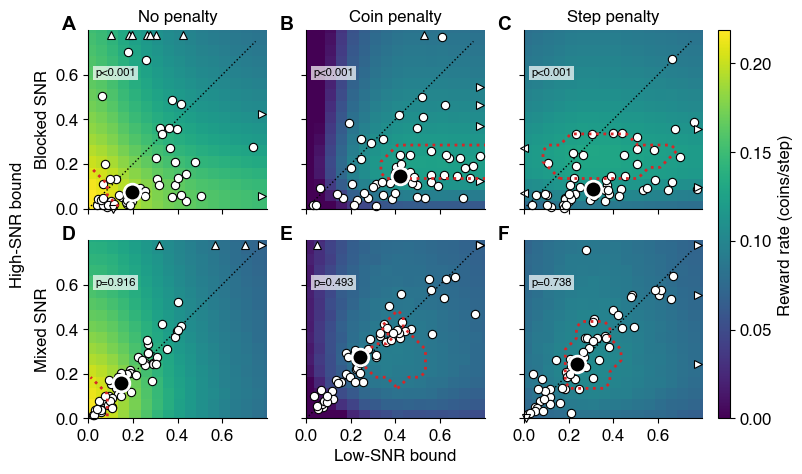

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure05.pdf (+ .png)


In [4]:
# ── Main figure: 2 rows (OL/MX) × 3 cols (blocks 1–3), heatmap panels ────────
WID = 15.6           # panel-grid width (cm); with the colorbar strip the figure is ~17.6 cm before labels
HTS = [4.53, 4.53]   # row heights (cm) — matches panel width for square axes
PSH = 0.8            # vertical panel separation (cm)
PSW = 1.0            # horizontal panel separation (cm)
CBAR_W   = 0.3       # colorbar width (cm)
CBAR_PAD = 0.4       # gap between panel grid and colorbar (cm)

n_rows  = len(tasks)
n_cols  = len(BLOCKS)
fig_h   = sum(HTS) + PSH * (n_rows - 1)
panel_w = (WID - PSW * (n_cols - 1)) / n_cols  # = 4.0 cm → square panels

hspace = PSH / np.mean(HTS)
wspace = PSW / panel_w

fig_w = WID + CBAR_PAD + CBAR_W   # total figure width, including colorbar strip

use_figure_style()

fig_main = plt.figure(figsize=(fig_w * CM, fig_h * CM))
panel_right = WID / fig_w   # fraction of total figure width used by the panel grid
gs = gridspec.GridSpec(n_rows, n_cols, figure=fig_main,
                       left=0, right=panel_right, bottom=0, top=1,
                       hspace=hspace, wspace=wspace)
axs = np.array([[fig_main.add_subplot(gs[r, c])
                 for c in range(n_cols)] for r in range(n_rows)])

# Column titles (top row only): the penalty condition, which is the same for both cohorts' block b;
# the row labels give the cohort (blocked vs. mixed SNR).

# One color scale for all panels (reward rate in coins per step in both rows).
vmax = max(m.max() for m in rr_matrices.values())

im = None
for row_idx, (task_label, task_type) in enumerate(tasks):
    for col_idx, block in enumerate(BLOCKS):
        ax = axs[row_idx, col_idx]
        panel_im = _plot_heatmap_panel(
            ax, *fit_bounds[(task_type, block)], RR_BOUNDS,
            rr_matrices.get((task_type, block)), vmax=vmax, lim=fit_limit[(task_type, block)])
        if panel_im is not None:
            im = panel_im

        if row_idx == 0:
            ax.set_title(CONDITION_LABELS[block])

        # y-axis: task-type row label only on leftmost column ("High-SNR
        # bound" is added once, centered across both rows, below)
        if col_idx == 0:
            ax.set_ylabel(TASK_ROW_LABELS[task_type])
        else:
            ax.tick_params(axis='y', labelleft=False)

        # x-axis: tick labels on bottom row only ("Low-SNR bound" is added
        # once, centered under the middle column, below)
        if row_idx != n_rows - 1:
            ax.tick_params(axis='x', labelbottom=False)

        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        add_panel_label(ax, chr(65 + row_idx * n_cols + col_idx))

# One colorbar, spanning both rows.
y0, y1 = axs[-1, 0].get_position().y0, axs[0, 0].get_position().y1
cax = fig_main.add_axes([(WID + CBAR_PAD) / fig_w, y0, CBAR_W / fig_w, y1 - y0])
cbar = fig_main.colorbar(im, cax=cax)
cbar.set_label('Reward rate (coins/step)')
cbar.set_ticks(np.arange(0, vmax + 1e-9, 0.05))

# Shared axis labels: "High-SNR bound" centered vertically between the two
# rows (just left of the per-row task-type labels), "Low-SNR bound" centered
# horizontally under the middle column (just below its tick labels).
fig_main.canvas.draw()
renderer = fig_main.canvas.get_renderer()

label_x0 = min(
    axs[0, 0].yaxis.label.get_window_extent(renderer=renderer).x0,
    axs[-1, 0].yaxis.label.get_window_extent(renderer=renderer).x0,
)
label_x_fig = fig_main.transFigure.inverted().transform((label_x0, 0))[0]
row_y0 = axs[-1, 0].get_position().y0
row_y1 = axs[0, 0].get_position().y1
fig_main.text(label_x_fig - 0.015, (row_y0 + row_y1) / 2, 'High-SNR bound',
              rotation=90, ha='right', va='center', fontsize=FS)

mid_col = n_cols // 2
mid_ax = axs[-1, mid_col]
tick_y0 = mid_ax.xaxis.get_tightbbox(renderer).y0
tick_y_fig = fig_main.transFigure.inverted().transform((0, tick_y0))[1]
col_x0, col_x1 = mid_ax.get_position().x0, mid_ax.get_position().x1
fig_main.text((col_x0 + col_x1) / 2, tick_y_fig - 0.015, 'Low-SNR bound',
              ha='center', va='top', fontsize=FS)

out = FIGURES_DIR / 'Figure05.pdf'
fig_main.savefig(out, dpi=300, bbox_inches='tight')
fig_main.savefig(out.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out} (+ .png)')

## Hi/lo SNR bound ratio

Per participant: median [IQR] of the high- / low-SNR plateau ratio (plateau-limit subjects left
out). Near-optimal region: the range of low- and high-SNR bounds, and of their ratio, over the grid
cells inside the dotted red contour (reward rate ≥ 95% of the maximum).

In [5]:
# ── Hi/Lo SNR bound ratio: per-participant and at optimal RR ──────────────────
print('Ratio of Hi-SNR to Lo-SNR bound\n')

for label, task_type in tasks:
    print(f'{label}:')
    for block in BLOCKS:
        lo, hi = fit_bounds[(task_type, block)]

        valid = np.isfinite(lo) & np.isfinite(hi) & (lo > 0) & ~fit_limit[(task_type, block)]
        ratio = hi[valid] / lo[valid]

        med      = np.median(ratio)
        q25, q75 = np.percentile(ratio, [25, 75])

        rm = rr_matrices[(task_type, block)]
        hi_idx, lo_idx = np.nonzero(rm >= 0.95 * rm.max())
        lo_r, hi_r = RR_BOUNDS[lo_idx], RR_BOUNDS[hi_idx]
        ratio_r = hi_r / lo_r
        rr_str = (f'lo {lo_r.min():.2f}-{lo_r.max():.2f}, hi {hi_r.min():.2f}-{hi_r.max():.2f}, '
                  f'ratio {ratio_r.min():.2f}-{ratio_r.max():.2f}')

        print(f'  Block {block}:  median [IQR] = {med:.3f} [{q25:.3f}, {q75:.3f}];'
              f'  near-optimal (>=95% max RR): {rr_str}')
    print()

Ratio of Hi-SNR to Lo-SNR bound

OL (Blocked SNR):
  Block 1:  median [IQR] = 0.376 [0.196, 0.974];  near-optimal (>=95% max RR): lo 0.01-0.11, hi 0.01-0.16, ratio 0.09-16.00
  Block 2:  median [IQR] = 0.349 [0.215, 0.549];  near-optimal (>=95% max RR): lo 0.36-0.81, hi 0.16-0.26, ratio 0.20-0.63
  Block 3:  median [IQR] = 0.306 [0.174, 0.553];  near-optimal (>=95% max RR): lo 0.11-0.66, hi 0.16-0.31, ratio 0.31-2.36

MX (Mixed SNR):
  Block 1:  median [IQR] = 0.978 [0.845, 1.162];  near-optimal (>=95% max RR): lo 0.01-0.06, hi 0.01-0.16, ratio 0.17-16.00
  Block 2:  median [IQR] = 1.007 [0.891, 1.134];  near-optimal (>=95% max RR): lo 0.26-0.51, hi 0.16-0.46, ratio 0.39-1.14
  Block 3:  median [IQR] = 1.019 [0.836, 1.155];  near-optimal (>=95% max RR): lo 0.21-0.41, hi 0.16-0.41, ratio 0.44-1.58



## Panel-by-panel bound statistics

For each panel (same paired lo/hi per-subject bound plateaus used in the figure's scatter (plateau-limit subjects left out) and Wilcoxon annotation):

- **Median [IQR] difference**: `hi_bound - lo_bound` per subject, summarized as median
  [25th-75th percentile], with the Wilcoxon signed-rank p-value for median difference != 0
  (identical test/data to the p-value annotated in each panel).
- **Spearman correlation**: rank correlation between each subject's lo and hi bound, with the
  p-value for correlation != 0.

In [6]:
# ── Panel-by-panel bound statistics: diff (hi - lo) and Spearman(lo, hi) ──────
stats_rows = []
for row_idx, (label, task_type) in enumerate(tasks):
    for col_idx, block in enumerate(BLOCKS):
        lo, hi = fit_bounds[(task_type, block)]
        valid = np.isfinite(lo) & np.isfinite(hi) & ~fit_limit[(task_type, block)]
        lo, hi = lo[valid], hi[valid]
        diff = hi - lo

        med, q25, q75 = np.median(diff), *np.percentile(diff, [25, 75])
        _, p_diff = scipy.stats.wilcoxon(lo, hi)
        rho, p_rho = scipy.stats.spearmanr(lo, hi)

        stats_rows.append({
            'Panel': chr(65 + row_idx * n_cols + col_idx),
            'Task': label,
            'Block': block,
            'n': valid.sum(),
            'Median diff [IQR]': f'{med:.3f} [{q25:.3f}, {q75:.3f}]',
            'p (diff != 0)': format_p(p_diff),
            'Spearman rho': format_rho(rho, 3),
            'p (rho != 0)': format_p(p_rho),
        })

stats_table = pd.DataFrame(stats_rows)
stats_table

,Panel,Task,Block,n,Median diff [IQR],p (diff != 0),Spearman rho,p (rho != 0)
0,A,OL (Blocked SNR),1,50,"-0.094 [-0.177, -0.004]",p<0.001,ρ=0.502,p<0.001
1,B,OL (Blocked SNR),2,55,"-0.224 [-0.400, -0.105]",p<0.001,ρ=0.383,p=0.004
2,C,OL (Blocked SNR),3,56,"-0.180 [-0.309, -0.097]",p<0.001,ρ=0.625,p<0.001
3,D,MX (Mixed SNR),1,56,"-0.002 [-0.020, 0.027]",p=0.916,ρ=0.935,p<0.001
4,E,MX (Mixed SNR),2,56,"0.003 [-0.027, 0.037]",p=0.493,ρ=0.938,p<0.001
5,F,MX (Mixed SNR),3,56,"0.002 [-0.039, 0.039]",p=0.738,ρ=0.884,p<0.001
